# SEER Breast-Cancer Regional Lymph-Node Dataset

## Dataset understanding, cohort construction and development splits

This notebook documents the SEER component of the joint Camelyon17–SEER model.

All patients in this cohort already have a breast-cancer diagnosis. The prediction target is regional lymph-node involvement:

- **N0 (`0`)**: no positive regional lymph nodes recorded.
- **N+ (`1`)**: at least one positive regional lymph node recorded.

The notebook uses only committed aggregate audits and summaries. It does not load patient identifiers, raw patient-level records, model predictions or the locked temporal-test features.

In [2]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

METRICS_DIR = PROJECT_ROOT / "artifacts" / "metrics"
CONFIG_DIR = PROJECT_ROOT / "configs"

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

## 1. Cohort overview

The exported SEER file initially contained multiple tumour records for some patients. A deterministic index-record rule retained one adult breast-cancer record per patient:

1. Select the earliest diagnosis year.
2. Resolve remaining cases using the smallest sequence rank.
3. Exclude patients younger than 18.
4. Remove records without a valid N0/N+ target.

In [3]:
with (
    METRICS_DIR / "seer_v2_cohort_audit.json"
).open("r", encoding="utf-8") as file:
    cohort_audit = json.load(file)

cohort = cohort_audit["cohort"]["index_cohort"]
flow = cohort_audit["cohort"]["flow"]

cohort_overview = pd.DataFrame(
    {
        "Measure": [
            "Raw tumour records",
            "Final unique patients",
            "Records removed as non-index",
            "Age range",
            "Diagnosis years",
            "N0 patients",
            "N+ patients",
            "N+ prevalence",
        ],
        "Value": [
            f"{flow['raw_records']:,}",
            f"{cohort['unique_patients']:,}",
            f"{flow['records_removed_as_non_index']:,}",
            f"{cohort['minimum_age']}–{cohort['maximum_age']}",
            f"{cohort['minimum_year']}–{cohort['maximum_year']}",
            f"{cohort['n0']:,}",
            f"{cohort['n_positive']:,}",
            f"{cohort['n_positive_percent']:.2f}%",
        ],
    }
)

cohort_overview

,Measure,Value
0,Raw tumour records,"756,356"
1,Final unique patients,"731,278"
2,Records removed as non-index,"25,066"
3,Age range,18–90
4,Diagnosis years,2010–2023
5,N0 patients,"503,794"
6,N+ patients,"227,484"
7,N+ prevalence,31.11%


In [ ]:
seer_table = pd.read_parquet(
    PROJECT_ROOT / "data" / "processed" / "seer_v2_model_table.parquet"
)

preview = seer_table.drop(
    columns=["Patient ID"],
    errors="ignore",
)

display(preview.head(5))
display(preview.tail(5))

## 2. Model input features

The final SEER model table contains 15 leakage-safe predictors: two numeric variables and 13 categorical variables. Patient identifiers, split information, diagnosis year and regional-node measurements are excluded from the model inputs.

In [5]:
with (
    CONFIG_DIR / "seer_features_v2.json"
).open("r", encoding="utf-8") as file:
    feature_config = json.load(file)

feature_descriptions = {
    "age_numeric": "Age at diagnosis",
    "tumor_size_mm": "Primary tumour size in millimetres",
    "Race recode (W, B, AI, API)": "Recorded race group",
    "Origin recode NHIA (Hispanic, Non-Hisp)": "Hispanic origin",
    "Primary Site - labeled": "Anatomical location within the breast",
    "Histologic Type ICD-O-3": "Tumour histological type",
    "Laterality": "Left or right breast",
    "grade_unified": "Harmonised tumour grade",
    "ER Status Recode Breast Cancer (1990+)": "Oestrogen-receptor status",
    "PR Status Recode Breast Cancer (1990+)": "Progesterone-receptor status",
    "Derived HER2 Recode (2010+)": "HER2 status",
    "Breast Subtype (2010+)": "Molecular breast-cancer subtype",
    "tumor_size_status": "Tumour-size measurement status",
    "t_stage_harmonized": "Harmonised primary-tumour stage",
    "m_stage_harmonized": "Harmonised distant-metastasis stage",
}

feature_rows = []

for feature in feature_config["model_numeric_features"]:
    feature_rows.append(
        {
            "Feature": feature,
            "Type": "Numeric",
            "Clinical meaning": feature_descriptions[feature],
        }
    )

for feature in feature_config["model_categorical_features"]:
    feature_rows.append(
        {
            "Feature": feature,
            "Type": "Categorical",
            "Clinical meaning": feature_descriptions[feature],
        }
    )

pd.DataFrame(feature_rows)

,Feature,Type,Clinical meaning
0,age_numeric,Numeric,Age at diagnosis
1,tumor_size_mm,Numeric,Primary tumour size in millimetres
2,"Race recode (W, B, AI, API)",Categorical,Recorded race group
3,"Origin recode NHIA (Hispanic, Non-Hisp)",Categorical,Hispanic origin
4,Primary Site - labeled,Categorical,Anatomical location within the breast
5,Histologic Type ICD-O-3,Categorical,Tumour histological type
6,Laterality,Categorical,Left or right breast
7,grade_unified,Categorical,Harmonised tumour grade
8,ER Status Recode Breast Cancer (1990+),Categorical,Oestrogen-receptor status
9,PR Status Recode Breast Cancer (1990+),Categorical,Progesterone-receptor status


## 3. Development and evaluation splits

Patients diagnosed from 2010–2019 form the development cohort. A deterministic stratified procedure assigns 90% to training and 10% to internal validation.

Patients diagnosed in 2020–2021 form the temporal validation set. The 2022–2023 temporal test set remains locked until the final evaluation.

In [6]:
split_summary = pd.read_csv(
    METRICS_DIR / "seer_v2_split_summary.csv"
)

split_names = {
    "train": "Training",
    "id_val": "Internal validation",
    "temporal_val": "Temporal validation",
    "temporal_test": "Temporal test — locked",
}

split_table = (
    split_summary.assign(
        split=split_summary["split"].map(split_names)
    )
    .rename(
        columns={
            "split": "Split",
            "patients": "Patients",
            "n0": "N0",
            "n_positive": "N+",
            "n_positive_percent": "N+ prevalence (%)",
            "minimum_year": "First year",
            "maximum_year": "Last year",
        }
    )
)

split_table.style.format(
    {
        "Patients": "{:,.0f}",
        "N0": "{:,.0f}",
        "N+": "{:,.0f}",
        "N+ prevalence (%)": "{:.2f}",
        "First year": "{:.0f}",
        "Last year": "{:.0f}",
    }
).hide(axis="index")

Split,Patients,N0,N+,N+ prevalence (%),First year,Last year
Training,"461,292","316,475","144,817",31.39,2010,2019
Internal validation,"51,241","35,157","16,084",31.39,2010,2019
Temporal validation,"107,249","74,137","33,112",30.87,2020,2021
Temporal test — locked,"111,496","78,025","33,471",30.02,2022,2023


### Class distribution

N0 is the majority class in every split, while N+ represents approximately 30–31% of patients. The small decrease in N+ prevalence over time is considered when interpreting temporal performance. Therefore, accuracy is reported together with ROC-AUC, balanced accuracy, sensitivity and specificity.

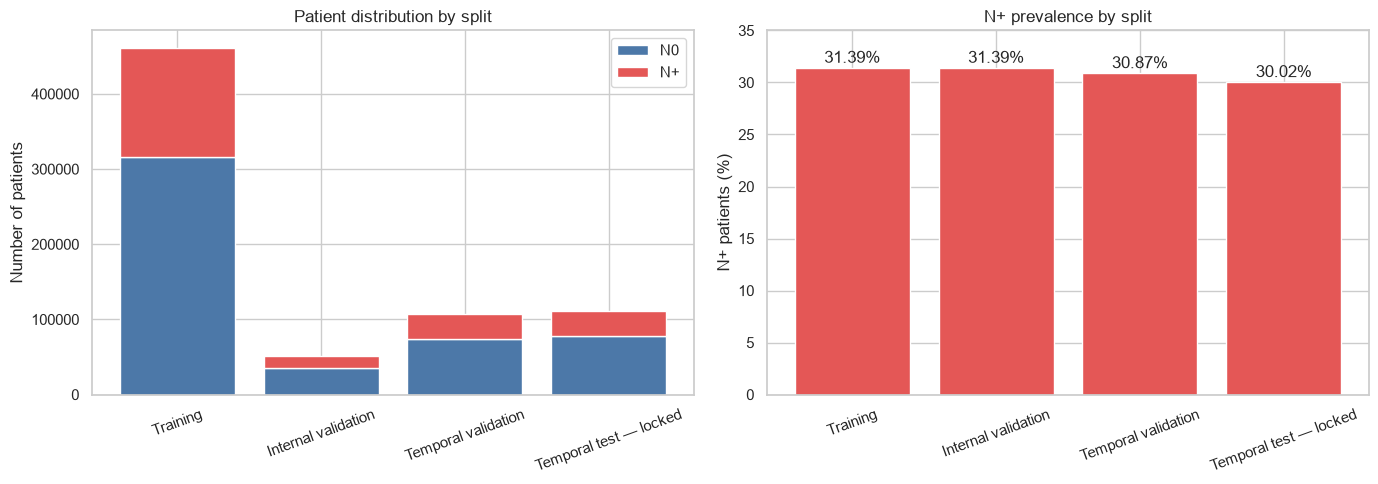

In [7]:
plot_data = split_summary.copy()
plot_data["Split"] = plot_data["split"].map(split_names)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    plot_data["Split"],
    plot_data["n0"],
    label="N0",
    color="#4C78A8",
)
axes[0].bar(
    plot_data["Split"],
    plot_data["n_positive"],
    bottom=plot_data["n0"],
    label="N+",
    color="#E45756",
)
axes[0].set_title("Patient distribution by split")
axes[0].set_ylabel("Number of patients")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend()

axes[1].bar(
    plot_data["Split"],
    plot_data["n_positive_percent"],
    color="#E45756",
)
axes[1].set_title("N+ prevalence by split")
axes[1].set_ylabel("N+ patients (%)")
axes[1].set_ylim(0, 35)
axes[1].tick_params(axis="x", rotation=20)

for index, value in enumerate(
    plot_data["n_positive_percent"]
):
    axes[1].text(
        index,
        value + 0.5,
        f"{value:.2f}%",
        ha="center",
    )

plt.tight_layout()
plt.show()

## 4. Leakage prevention

Regional lymph-node information directly defines the N0/N+ target, so it must not be provided to the model as an input. Patient identifiers, split labels and administrative variables are also excluded.

Raw era-specific staging variables are replaced by harmonised T- and M-stage features so that the same clinical definitions can be used across 2010–2023.

In [8]:
excluded_inputs = pd.DataFrame(
    [
        {
            "Excluded variable": variable,
            "Reason": reason,
        }
        for variable, reason in feature_config[
            "forbidden_model_inputs"
        ].items()
    ]
)

excluded_inputs.style.hide(axis="index")

Excluded variable,Reason
Patient ID,Identifier used only for privacy-safe cohort and split validation.
Sequence number,Administrative tumor order used only for deterministic index-record selection.
Year of diagnosis,Used for temporal splitting and excluded to reduce temporal shortcut learning.
Regional nodes positive (1988+),Direct source of the prediction target.
Regional nodes examined (1988+),Closely tied to how the target was measured and could leak procedural information.
Diagnostic Confirmation,Administrative confirmation field and nearly constant in this cohort.
Grade Recode (thru 2017),Replaced by grade_unified.
Grade Clinical (2018+),Replaced by grade_unified.
Age recode with single ages and 90+,Replaced by age_numeric.
Tumor Size Over Time Recode (1988+),Replaced by tumor_size_mm and tumor_size_status.


## 5. Feature and prevalence drift

Population Stability Index (PSI) compares each development split with the training distribution:

- PSI below 0.10: small drift
- PSI from 0.10 to below 0.25: moderate drift
- PSI of 0.25 or above: large drift

The analysis is also repeated separately within N0 and N+ patients. The locked temporal-test set is not included.

In [9]:
drift_summary = pd.read_csv(
    METRICS_DIR
    / "seer_v2_development_drift_summary.csv"
)

prevalence_drift = pd.read_csv(
    METRICS_DIR
    / "seer_v2_development_prevalence_drift.csv"
)

drift_table = (
    drift_summary.merge(
        prevalence_drift[
            [
                "comparison",
                "absolute_percentage_point_change",
            ]
        ],
        on="comparison",
    )
    .assign(
        comparison=lambda data: data["comparison"].map(
            {
                "id_val": "Internal validation",
                "temporal_val": "Temporal validation",
            }
        )
    )
    .rename(
        columns={
            "comparison": "Comparison",
            "overall_maximum_psi": "Maximum overall PSI",
            "class_conditional_maximum_psi":
                "Maximum class-conditional PSI",
            "overall_moderate_or_large_features":
                "Features with PSI ≥ 0.10",
            "absolute_percentage_point_change":
                "N+ prevalence change (percentage points)",
        }
    )
    [
        [
            "Comparison",
            "Maximum overall PSI",
            "Maximum class-conditional PSI",
            "Features with PSI ≥ 0.10",
            "N+ prevalence change (percentage points)",
        ]
    ]
)

drift_table.style.format(
    {
        "Maximum overall PSI": "{:.4f}",
        "Maximum class-conditional PSI": "{:.4f}",
        "N+ prevalence change (percentage points)": "{:+.3f}",
    }
).hide(axis="index")

Comparison,Maximum overall PSI,Maximum class-conditional PSI,Features with PSI ≥ 0.10,N+ prevalence change (percentage points)
Internal validation,0.0034,0.0094,0,-0.005
Temporal validation,0.0855,0.0901,0,-0.520


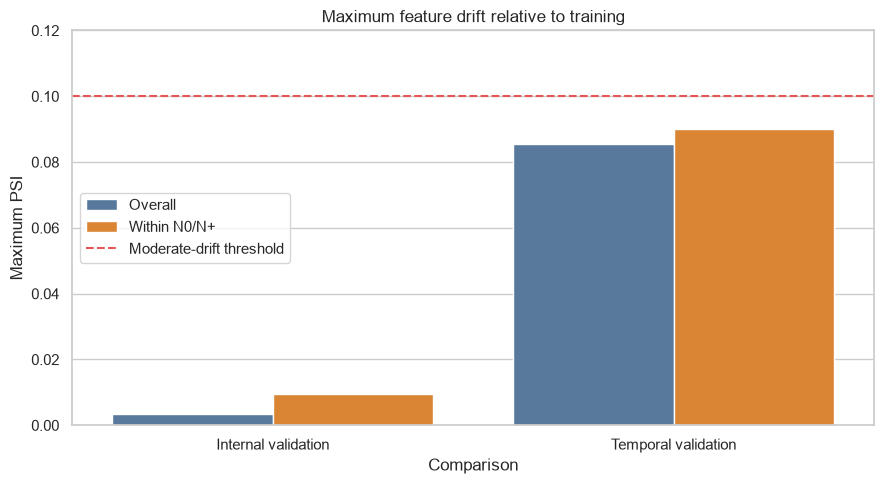

In [10]:
drift_plot = (
    drift_summary[
        [
            "comparison",
            "overall_maximum_psi",
            "class_conditional_maximum_psi",
        ]
    ]
    .rename(
        columns={
            "comparison": "Comparison",
            "overall_maximum_psi": "Overall",
            "class_conditional_maximum_psi":
                "Within N0/N+",
        }
    )
)

drift_plot["Comparison"] = drift_plot[
    "Comparison"
].map(
    {
        "id_val": "Internal validation",
        "temporal_val": "Temporal validation",
    }
)

drift_plot = drift_plot.melt(
    id_vars="Comparison",
    var_name="Analysis",
    value_name="Maximum PSI",
)

plt.figure(figsize=(9, 5))

axis = sns.barplot(
    data=drift_plot,
    x="Comparison",
    y="Maximum PSI",
    hue="Analysis",
    palette=["#4C78A8", "#F58518"],
)

axis.axhline(
    0.10,
    color="#E45756",
    linestyle="--",
    label="Moderate-drift threshold",
)
axis.set_ylim(0, 0.12)
axis.set_title("Maximum feature drift relative to training")
axis.legend(title="")

plt.tight_layout()
plt.show()

## 6. Training-only preprocessing

All preprocessing parameters are fitted using the training split only.

Numeric variables are median-imputed when necessary and standardised using training statistics. Categorical values are mapped using training vocabularies and represented by learned embeddings. Categories not observed during training receive an unknown-category index.

Patient identifiers are never included in the model tensors, and the temporal-test set is not loaded during preprocessing.

In [11]:
with (
    METRICS_DIR / "seer_v2_preprocessing_audit.json"
).open("r", encoding="utf-8") as file:
    preprocessing_audit = json.load(file)

numeric_table = pd.DataFrame(
    [
        {
            "Feature": feature,
            "Training mean": values["mean"],
            "Training median": values["median"],
            "Training scale": values["scale"],
            "Missing training values":
                values["training_missing_count"],
        }
        for feature, values in preprocessing_audit[
            "numeric_statistics"
        ].items()
    ]
)

numeric_table.style.format(
    {
        "Training mean": "{:.2f}",
        "Training median": "{:.2f}",
        "Training scale": "{:.2f}",
        "Missing training values": "{:,.0f}",
    }
).hide(axis="index")

Feature,Training mean,Training median,Training scale,Missing training values
age_numeric,60.66,61.00,12.83,0
tumor_size_mm,21.46,17.00,17.25,"15,697"


In [12]:
categorical_table = pd.DataFrame(
    [
        {
            "Feature": feature,
            "Training categories": preprocessing_audit[
                "categorical_summary"
            ][feature]["training_cardinality"],
            "Embedding rows": preprocessing_audit[
                "categorical_summary"
            ][feature]["num_embeddings"],
            "Embedding dimension": preprocessing_audit[
                "categorical_summary"
            ][feature]["embedding_dimension"],
        }
        for feature in feature_config[
            "model_categorical_features"
        ]
    ]
)

categorical_table.style.format(
    {
        "Training categories": "{:,.0f}",
        "Embedding rows": "{:,.0f}",
        "Embedding dimension": "{:,.0f}",
    }
).hide(axis="index")

Feature,Training categories,Embedding rows,Embedding dimension
"Race recode (W, B, AI, API)",5,6,4
"Origin recode NHIA (Hispanic, Non-Hisp)",2,3,4
Primary Site - labeled,9,10,4
Histologic Type ICD-O-3,118,119,11
Laterality,5,6,4
grade_unified,5,6,4
ER Status Recode Breast Cancer (1990+),4,5,4
PR Status Recode Breast Cancer (1990+),4,5,4
Derived HER2 Recode (2010+),4,5,4
Breast Subtype (2010+),6,7,4


### Preprocessing quality checks

Unknown categorical values are mapped safely instead of being treated as errors. Missing tumour sizes are imputed using the training median. Patient identifiers are excluded from every tensor.

In [13]:
split_audits = preprocessing_audit[
    "development_split_audits"
]

quality_table = pd.DataFrame(
    [
        {
            "Split": split_names[split],
            "Rows": values["rows"],
            "Unknown categorical values": sum(
                values[
                    "categorical_unknown_counts"
                ].values()
            ),
            "Missing age values":
                values["numeric_missing_counts"][
                    "age_numeric"
                ],
            "Missing tumour-size values":
                values["numeric_missing_counts"][
                    "tumor_size_mm"
                ],
            "Patient IDs in tensors":
                values["patient_identifiers_in_tensors"],
        }
        for split, values in split_audits.items()
    ]
)

quality_table.style.format(
    {
        "Rows": "{:,.0f}",
        "Unknown categorical values": "{:,.0f}",
        "Missing age values": "{:,.0f}",
        "Missing tumour-size values": "{:,.0f}",
    }
).hide(axis="index")

Split,Rows,Unknown categorical values,Missing age values,Missing tumour-size values,Patient IDs in tensors
Internal validation,"51,241",1,0,"1,767",False
Temporal validation,"107,249",4,0,"3,163",False
Training,"461,292",0,0,"15,697",False


## 7. SEER dataset summary

The final SEER cohort contains 731,278 adult breast-cancer patients diagnosed from 2010–2023.

The prediction target is regional lymph-node involvement:

- **N0:** no positive regional lymph nodes recorded.
- **N+:** at least one positive regional lymph node recorded.

The model uses 15 leakage-safe clinical predictors. Direct node measurements, patient identifiers, diagnosis year, split labels and administrative variables are excluded.

Development analysis found:

- Stable class proportions across the training and validation splits.
- No feature with moderate or large PSI drift.
- Very few categorical values unseen during training.
- No patient overlap caused by multiple tumour records.
- No use of the locked 2022–2023 temporal-test set.

This produces a large, clinically meaningful and temporally structured dataset for the tabular path of the joint Camelyon17–SEER model.